# Julia Sets

In this notebook I compute and plot the filled Julia set $K_c$ of the polynomial $Q_c(z) = z^2 + c$. The parameter $c$ and the region that is drawn can be changed in the **Parameters** cell (section 4).

It is the companion of `mandelbrot.ipynb`: there $z_0 = 0$ is fixed and $c$ varies; here $c$ is fixed and $z_0$ varies.

## 1. Definition

For a fixed $c \in \mathbb{C}$, the **filled Julia set** is

$$K_c = \{\, z_0 \in \mathbb{C} : (Q_c^{\,n}(z_0))_{n\ge 0} \text{ is bounded} \,\},$$

and the **Julia set** $J_c$ is its boundary, $J_c = \partial K_c$.

There is a direct relation with the Mandelbrot set $\mathcal{M}$ (Fatou–Julia dichotomy):

- if $c \in \mathcal{M}$, then $J_c$ is **connected**;
- if $c \notin \mathcal{M}$, then $K_c = J_c$ is a Cantor set ("dust").

This explains why in $\mathcal{M}$ we follow the orbit of $0$: it is the critical point of $Q_c$, and its behaviour decides the topology of $J_c$.

## 2. Escape criterion

**Claim.** Let $R \ge \max(2, |c|)$. If $|z_n| > R$ for some $n$, then $|z_k| \to \infty$.

*Idea of the proof.* If $|z| > R \ge |c|$ and $|z| > 2$:

$$|z^2 + c| \ge |z|^2 - |c| > |z|^2 - |z| = |z|\,(|z| - 1),$$

and since $|z| - 1 > 1$ the modulus grows faster and faster and tends to infinity.

Consequence: $K_c$ lies inside the disc of radius $R$, so it is enough to draw a window that contains it (for most values of $c$ of interest, $[-1.5, 1.5]^2$ or $[-2, 2]^2$).

The escape radius in the code is 256, which satisfies $R \ge \max(2, |c|)$ for all the values of $c$ used here. As with Mandelbrot, the number of iterations is finite (`max_iter`), so the result is an approximation.

## 3. Smooth colouring

As in the other notebook, instead of the integer number of iterations I use

$$\nu = N + 1 - \log_2\!\big(\ln |z_N|\big),$$

where $N$ is the first iteration at which $|z_N|$ exceeds the escape radius. Points that never escape (an approximation of $K_c$) are drawn in black.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

## 4. Parameters

Change `c` to any complex number.

In [2]:
# --- parameter of the polynomial z^2 + c ---
c = -0.1226 + 0.7449j     # Douady's rabbit

# --- region of the plane to draw (z_0 = x + iy) ---
x_min, x_max = -1.6, 1.6
y_min, y_max = -1.6, 1.6

# --- quality ---
resolution = 1000      # pixels per side
max_iter = 300         # maximum iterations

# --- appearance ---
cmap = "twilight_shifted"
gamma = 0.35

# --- save the figure ---
save = True
filename = "images/julia.png"

## 5. Computation

In [3]:
def julia(c, x_min, x_max, y_min, y_max, resolution, max_iter, radius=256):
    if radius < max(2, abs(c)):
        raise ValueError("The escape radius must be >= max(2, |c|)")

    # grid of initial values z_0
    x = np.linspace(x_min, x_max, resolution)
    y = np.linspace(y_min, y_max, resolution)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y

    nu = np.full(Z.shape, np.nan)           # NaN = has not escaped (is in K_c)
    active = np.ones(Z.shape, dtype=bool)

    for n in range(1, max_iter + 1):
        Z[active] = Z[active] ** 2 + c
        escaped = active & (np.abs(Z) > radius)
        nu[escaped] = n + 1 - np.log2(np.log(np.abs(Z[escaped])))
        active &= ~escaped
        if not active.any():
            break
    return nu


def draw(nu, x_min, x_max, y_min, y_max, title, ax):
    palette = plt.get_cmap(cmap).copy()
    palette.set_bad("black")
    ax.imshow(np.ma.masked_invalid(nu),
              extent=[x_min, x_max, y_min, y_max],
              origin="lower", cmap=palette, norm=PowerNorm(gamma=gamma))
    ax.set_title(title)
    ax.set_xlabel("Re($z$)")
    ax.set_ylabel("Im($z$)")


def c_label(c):
    sign = "+" if c.imag >= 0 else "-"
    return f"c = {c.real:.4f} {sign} {abs(c.imag):.4f}i"

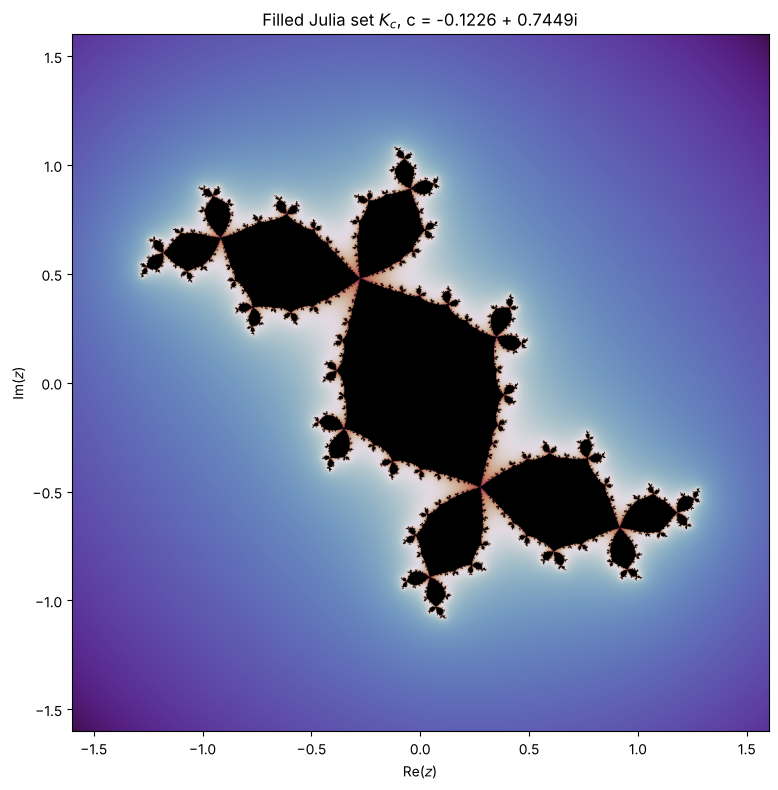

In [4]:
nu = julia(c, x_min, x_max, y_min, y_max, resolution, max_iter)

fig, ax = plt.subplots(figsize=(8, 8))
draw(nu, x_min, x_max, y_min, y_max, "Filled Julia set $K_c$, " + c_label(c), ax)
fig.tight_layout()

if save:
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    fig.savefig(filename, dpi=150)
plt.show()

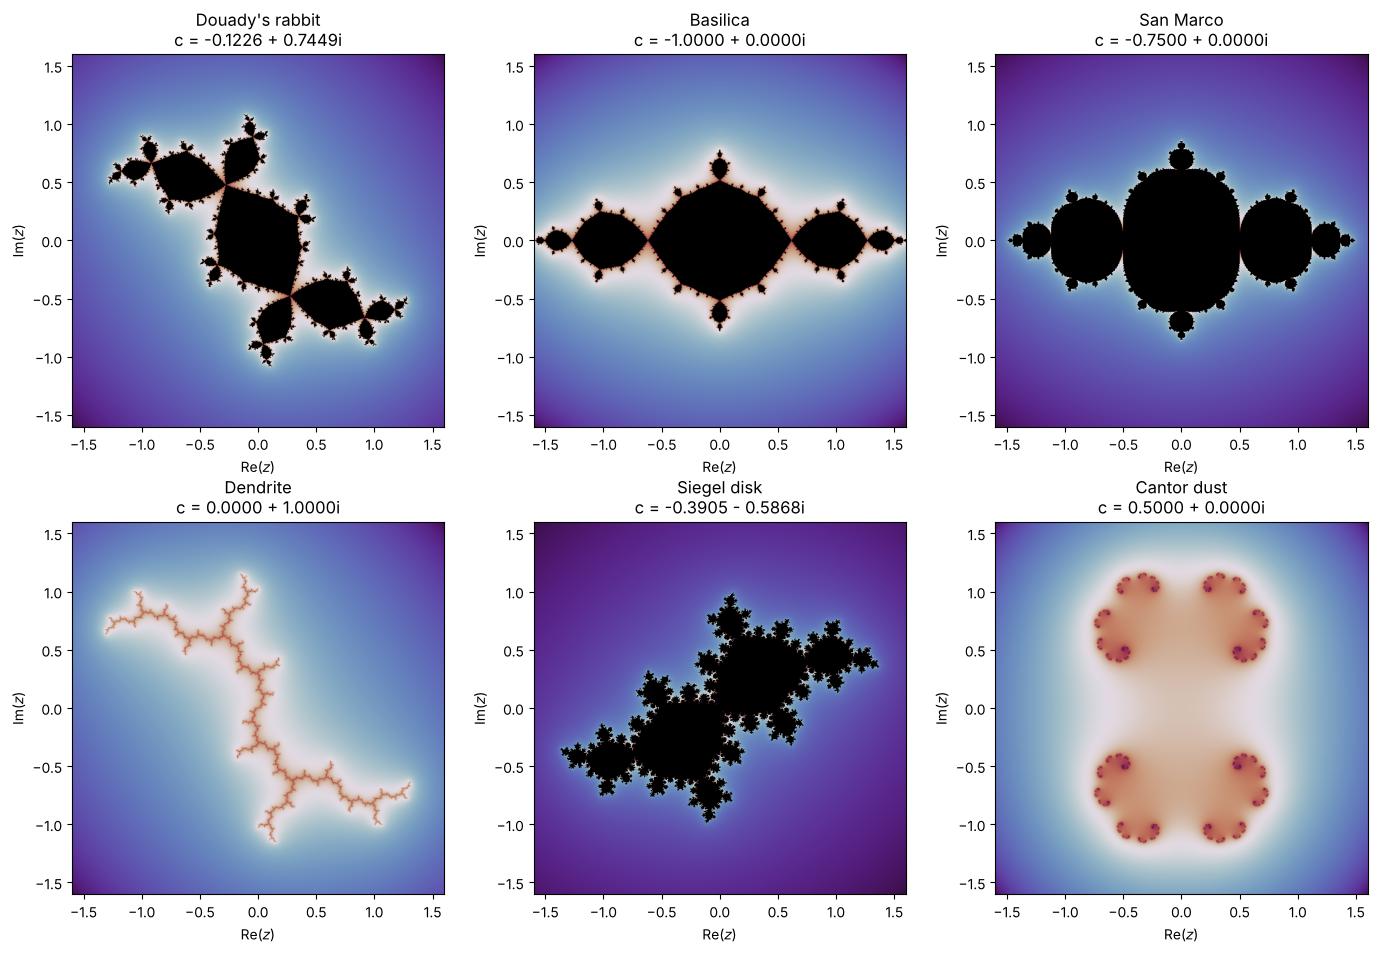

In [5]:
# Compare several values of c at once (the dictionary can be edited)
lam = np.exp(2j * np.pi * (np.sqrt(5) - 1) / 2)

cases = {
    "Douady's rabbit": -0.1226 + 0.7449j,
    "Basilica": -1.0 + 0.0j,
    "San Marco": -0.75 + 0.0j,
    "Dendrite": 1j,
    "Siegel disk": lam / 2 - lam**2 / 4,
    "Cantor dust": 0.5 + 0.0j,
}

fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
for ax, (name, cc) in zip(axes.ravel(), cases.items()):
    nu_cc = julia(cc, -1.6, 1.6, -1.6, 1.6, 600, 300)
    draw(nu_cc, -1.6, 1.6, -1.6, 1.6, f"{name}\n{c_label(cc)}", ax)
fig.tight_layout()
if save:
    fig.savefig("images/julia_gallery.png", dpi=130)
plt.show()